# 17 微分(Differential)

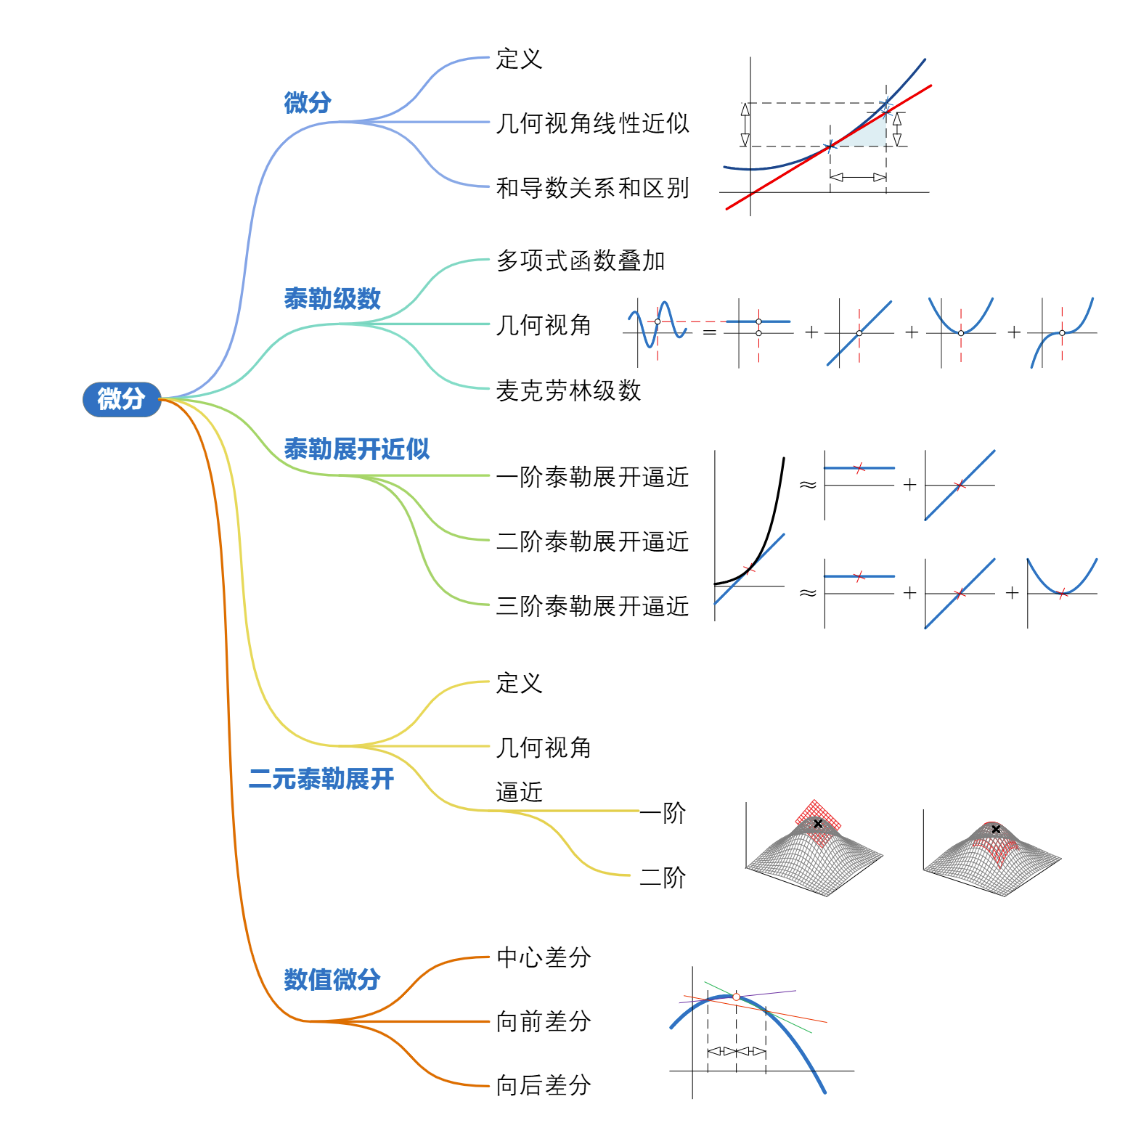

## 17.1 几何角度看微分：线性近似

微分(differential)是函数的局部变化的一种线性描述。微分可以近似地描述当数自变量取值出现足够小 $\Delta x$ 变化时，函数值变化 $\Delta y$。

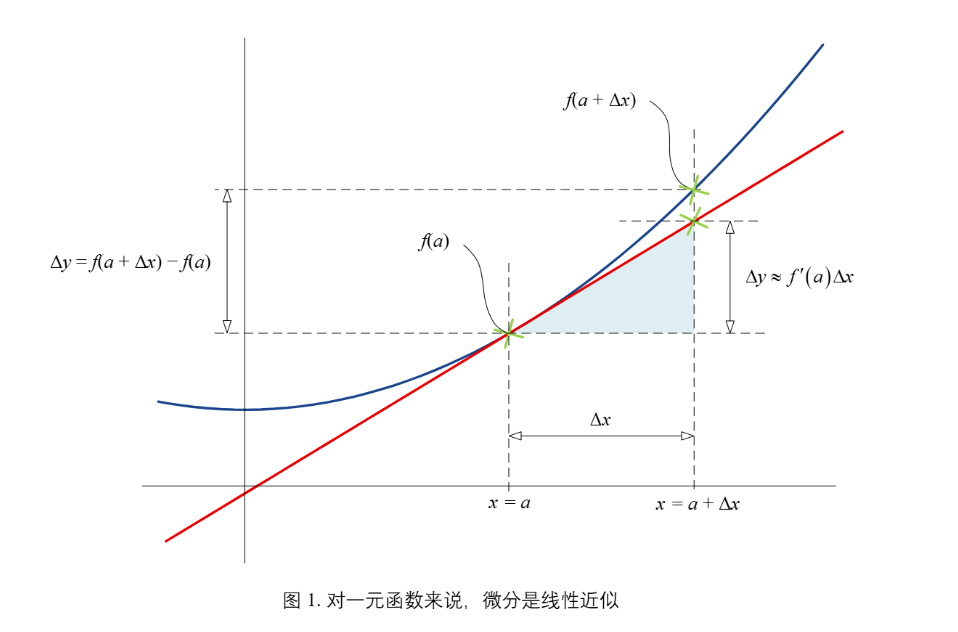

$f(a+\Delta x)$的近似写成:
$$
f(a+\Delta x) \approx  f'(a)\Delta x + f(a)
$$

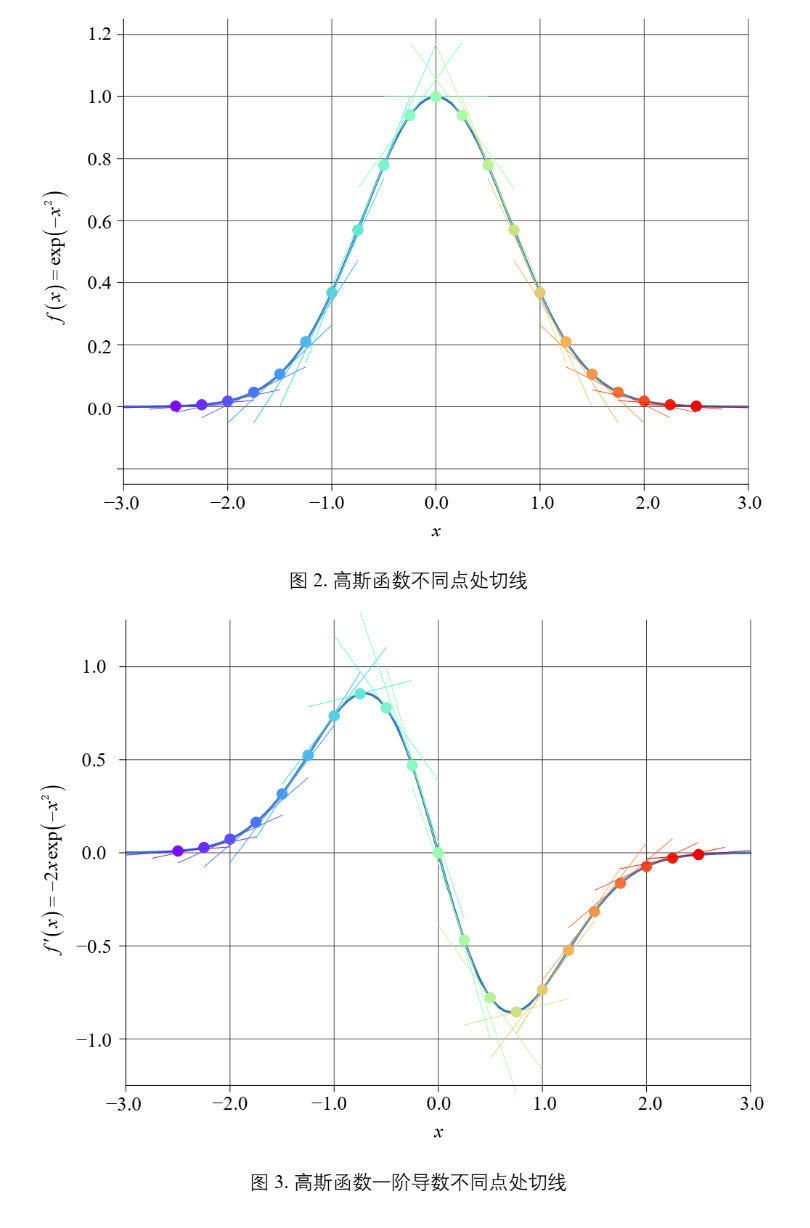

## 17.2 泰勒级数：多项式函数近似

当<font color="blue">展开点</font>(expansion point)为 $x=a$ 时，一元函数 $f(x)$ 泰勒展开(Taylor expansion)形式为:
$$
\begin{aligned}
f(x)
&=\sum_{n=0}^{\infty}\frac{f^{(n)}(a)}{n!}(x-a)^n\\
&=\underbrace{f(a)}_{\text{Constant}}
+\underbrace{\frac{f'(a)}{1!}(x-a)}_{\text{Linear}}
+\underbrace{\frac{f''(a)}{2!}(x-a)^2}_{\text{Quadratic}}
+\underbrace{\frac{f'''(a)}{3!}(x-a)^3}_{\text{Cubic}}
+\cdots
\end{aligned}
$$

实际应用中，在应用泰勒公式近似计算时需要截断，也就是只取有限项。
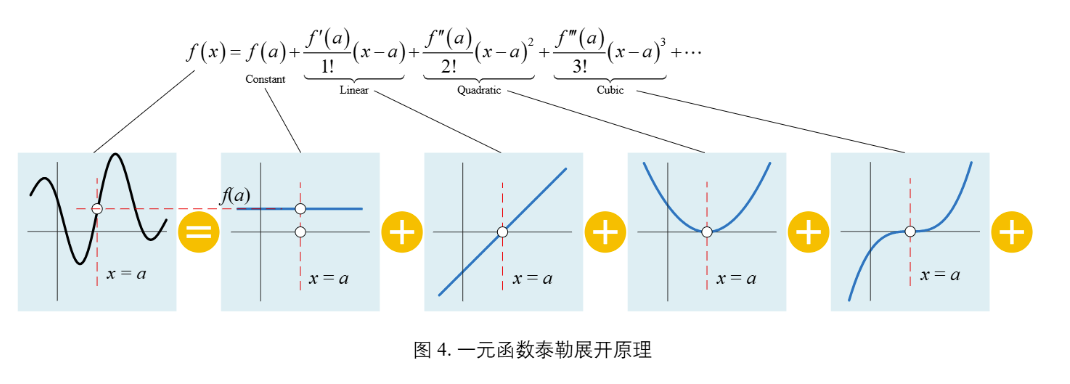

In [29]:
from sympy import lambdify, diff, evalf, sin, exp
from sympy.abc import x
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm

In [30]:
f_x = exp(-x**2)
f_x

exp(-x**2)

In [31]:
x_array = np.linspace(-3, 3, 100)
x_0_array = np.linspace(-2.5, 2.5, 21)

In [32]:
f_x_fcn = lambdify(x, f_x)
f_x_array = f_x_fcn(x_array)

In [33]:
colors = plt.cm.rainbow(np.linspace(0, 1, len(x_0_array)))

In [34]:
f_x_1_diff = diff(f_x, x, 1)
f_x_1_diff

-2*x*exp(-x**2)

In [35]:
f_x_1_diff_fcn = lambdify(x, f_x_1_diff)

In [36]:
f_x_2_diff = diff(f_x, x, 2)
f_x_2_diff

2*(2*x**2 - 1)*exp(-x**2)

In [37]:
f_x_2_diff_fcn = lambdify(x, f_x_2_diff)

In [38]:
f_x_3_diff = diff(f_x, x, 3)
f_x_3_diff

4*x*(3 - 2*x**2)*exp(-x**2)

In [39]:
f_x_3_diff_fcn = lambdify(x, f_x_3_diff)

(-0.25, 1.25)

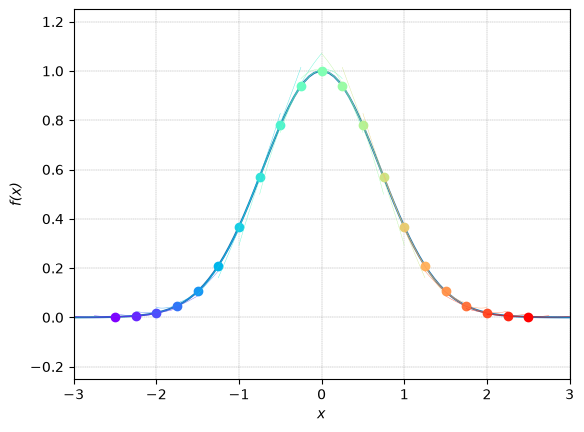

In [40]:
fig, ax = plt.subplots()

ax.plot(x_array, f_x_array, linewidth=1.5)
ax.set_xlabel(r"$\it{x}$")
ax.set_ylabel(r"$\it{f}(\it{x})$")

for i in np.arange(len(x_0_array)):
    color = colors[i, :]
    x_0 = x_0_array[i]
    y_0 = f_x.evalf(subs={x:x_0})
    x_t_array = np.linspace(x_0 - 0.5, x_0 + 0.5, 50)

    b = f_x_1_diff.evalf(subs={x: x_0})
    a = f_x_2_diff.evalf(subs={x: x_0})

    second_order_f = a/2 * (x - x_0) ** 2 + b * (x - x_0) + y_0
    second_order_f_fcn = lambdify(x, second_order_f)
    second_order_f_array = second_order_f_fcn(x_t_array)

    ax.plot(x_t_array, second_order_f_array, linewidth=0.25, color=color)
    ax.plot(x_0, y_0, marker=".", color=color, markersize=12)

ax.grid(linestyle="--", linewidth=0.25, color=[0.5, 0.5, 0.5])
ax.set_xlim(x_array.min(), x_array.max())
ax.set_ylim(-0.25, 1.25)

(-1.25, 1.25)

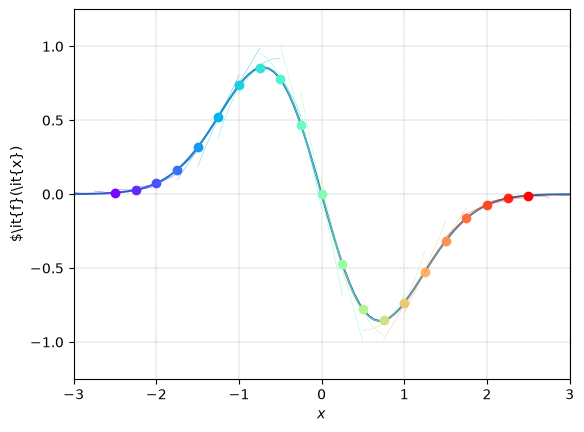

In [41]:
f_x_1_diff_array = f_x_1_diff_fcn(x_array)

fig, ax = plt.subplots()

ax.plot(x_array, f_x_1_diff_array, linewidth=1.5)
ax.set_xlabel(r"$\it{x}$")
ax.set_ylabel(r"$\it{f}(\it{x})")

for i in np.arange(len(x_0_array)):
    color = colors[i, :]
    x_0 = x_0_array[i]
    y_0 = f_x_1_diff.evalf(subs={x:x_0})
    x_t_array = np.linspace(x_0 - 0.5, x_0 + 0.5, 50)

    b = f_x_2_diff.evalf(subs={x: x_0})
    a = f_x_3_diff.evalf(subs={x: x_0})

    second_order_f = a/2 * (x - x_0) ** 2 + b * (x - x_0) + y_0
    second_order_f_fcn = lambdify(x, second_order_f)
    second_order_f_array = second_order_f_fcn(x_t_array)

    ax.plot(x_t_array, second_order_f_array, linewidth=0.25, color=color)
    ax.plot(x_0, y_0, marker=".", color=color, markersize=12)

ax.grid(linestyle="--", linewidth=0.25, color=[0.5, 0.5, 0.5])
ax.set_xlim(x_array.min(), x_array.max())
ax.set_ylim(-1.25, 1.25)

## 17.3 多项式近似和误差

再次强调，泰勒展开的核心是用一系列多项式函数叠加来逼近某个函数。实际应用中，泰勒级数常用来近似计算复杂非线性函数，并估计误差。

In [42]:
from sympy import latex, lambdify, diff, sin, log, exp, series
from sympy.abc import x
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm

In [43]:
f_x = exp(x)
f_x

exp(x)

In [44]:
x_array = np.linspace(-2, 2, 100)
x_0 = 0 # 泰勒展开的中心点
y_0 = f_x.evalf(subs={x:x_0})
f_x_fcn = lambdify(x, f_x)
f_x_array = f_x_fcn(x_array)

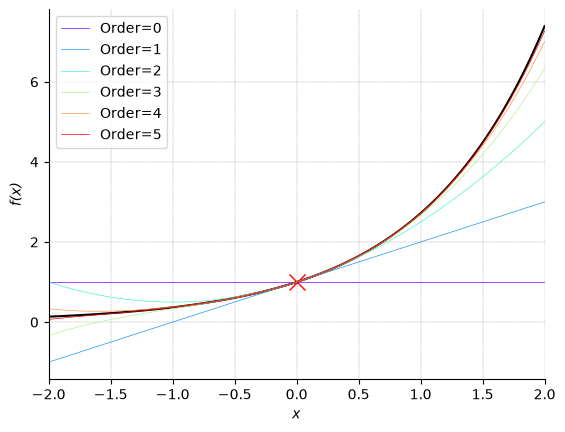

In [53]:
# 绘制函数和泰勒展开项
fig, ax = plt.subplots()

ax.plot(x_array, f_x_array, "k", linewidth=1.5)
ax.plot(x_0, y_0, "xr", markersize=12) # 标记展开点 (x_0, y_0)
ax.set_xlabel(r"$\it{x}$")
ax.set_ylabel(r"$\it{f}(\it{x})$")

highest_order = 5 # 设置泰勒展开的最高阶数
order_array = np.arange(0, highest_order + 1)
colors = plt.cm.rainbow(np.linspace(0, 1, len(order_array)))

i = 0
for order in order_array:
    f_series = f_x.series(x, x_0, order+1).removeO()  # 计算泰勒展开项（去除高阶小量）
    f_series_fcn = lambdify(x, f_series)
    f_series_array = f_series_fcn(x_array)

    ax.plot(x_array, 0 * x_array + f_series_array, linewidth=0.5, color=colors[i, :], label="Order=%0.0f" % order)
    i += 1

ax.grid(linewidth=0.25, color=[0.5, 0.5, 0.5], linestyle = "--")
ax.set_xlim(x_array.min(), x_array.max())
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.legend()

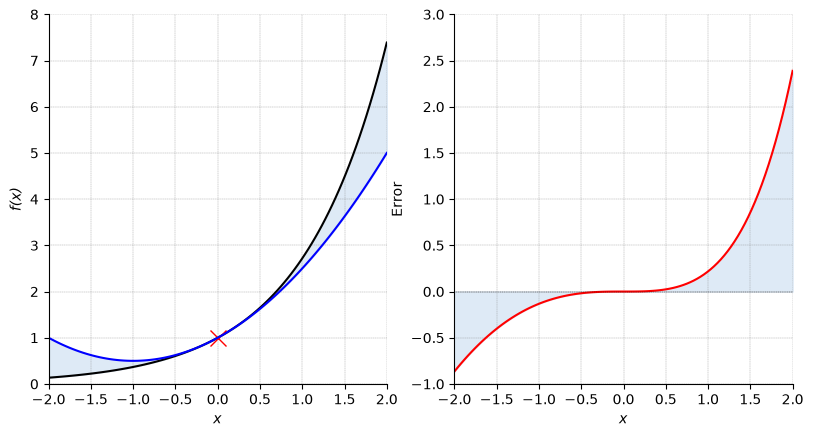

In [54]:
fig = plt.figure(figsize=plt.figaspect(0.5))
ax = fig.add_subplot(1, 2, 1)

ax.plot(x_array, f_x_array, "k", linewidth=1.5)
ax.plot(x_0, y_0, "xr", markersize=12) # 标记展开点 (x_0, y_0)
ax.set_xlabel(r"$\it{x}$")
ax.set_ylabel(r"$\it{f}(\it{x})$")

highest_order = 2

f_series = f_x.series(x, x_0, highest_order+1).removeO()  # 计算泰勒展开项（去除高阶小量）
f_series_fcn = lambdify(x, f_series)
f_series_array = f_series_fcn(x_array)
f_series_array = x_array * 0 + f_series_array

ax.plot(x_array, f_series_array, linewidth=1.5, color="b")

ax.fill_between(x_array, f_x_array, f_series_array, color="#DEEAF6")

ax.grid(linewidth=0.25, color=[0.5, 0.5, 0.5], linestyle = "--")
ax.set_xlim(x_array.min(), x_array.max())
ax.set_ylim(np.floor(f_x_array.min()), np.ceil(f_x_array.max()))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax = fig.add_subplot(1, 2, 2)
error = f_x_array - f_series_array
ax.plot(x_array, error, "r", linewidth=1.5)
ax.fill_between(x_array, error, color="#Deeaf6")
plt.axhline(y=0, color="k", linestyle="--", linewidth=0.25)
ax.set_xlabel(r"$\it{x}$")
ax.set_ylabel("Error")

ax.grid(linewidth=0.25, color=[0.5, 0.5, 0.5], linestyle = "--")
ax.set_xlim(x_array.min(), x_array.max())
ax.set_ylim(np.floor(error.min()), np.ceil(error.max()))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

## 17.4 二元泰勒展开：用多项式曲面近似

给定二元函数 $f(x_1，x2)$，它的泰勒展开可以写成:
$$
\begin{aligned}
f(x_1,x_2)
={}&\underbrace{f(a,b)}_{\text{Constant}}
+\underbrace{
f_{x_1}(a,b)(x_1-a)+f_{x_2}(a,b)(x_2-b)
}_{\text{Plane}}\\
&+\underbrace{
\frac{1}{2!}\left[
f_{x_1x_1}(a,b)(x_1-a)^2
+2f_{x_1x_2}(a,b)(x_1-a)(x_2-b)
+f_{x_2x_2}(a,b)(x_2-b)^2
\right]
}_{\text{Quadratic}}
+\cdots
\end{aligned}
$$

写成矩阵运算形式:
$$
f(x_1,x_2)
=f(a,b)
+
\begin{bmatrix}
f_{x_1}(a,b)\\
f_{x_2}(a,b)
\end{bmatrix}^{\mathrm T}
\begin{bmatrix}
x_1-a\\
x_2-b
\end{bmatrix}
+
\frac{1}{2!}
\begin{bmatrix}
x_1-a\\
x_2-b
\end{bmatrix}^{\mathrm T}
\begin{bmatrix}
f_{x_1x_1}(a,b) & f_{x_2x_1}(a,b)\\
f_{x_1x_2}(a,b) & f_{x_2x_2}(a,b)
\end{bmatrix}
\begin{bmatrix}
x_1-a\\
x_2-b
\end{bmatrix}
+\cdots
$$

In [55]:
from sympy import lambdify, diff, exp, latex, simplify
from sympy.abc import x, y
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm

In [56]:
num = 301
x_array = np.linspace(-1.5, 1.5, num)
y_array = np.linspace(-1.5, 1.5, num)
xx, yy = np.meshgrid(x_array, y_array)
num_stride = 10 # 绘制时的步长

In [57]:
f_xy = exp(-x ** 2 - y ** 2)
f_xy_fcn = lambdify([x, y], f_xy)
f_xy_zz = f_xy_fcn(xx, yy)

In [60]:
x_a = -0.1
y_b = -0.2

In [61]:
# 创建局部网络
x_a_array = np.linspace(x_a-0.5, x_a+0.5, 101)
y_b_array = np.linspace(y_b-0.5, y_b+0.5, 101)
xx_local, yy_local = np.meshgrid(x_a_array, y_b_array)
f_xy_zz_loc = f_xy_fcn(xx_local, yy_local)

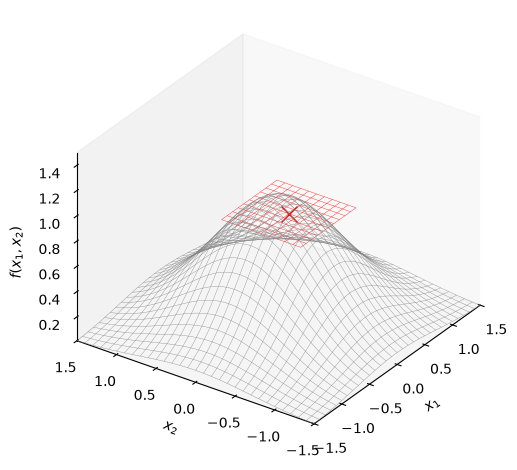

In [69]:
# 零阶近似(常数近似)
f_ab = f_xy_fcn(x_a, y_b)

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ax.plot_wireframe(xx, yy, f_xy_zz,
                 color=[0.5, 0.5, 0.5], rstride=num_stride, cstride=num_stride, linewidth=0.25)

approx_zero_order = f_ab + xx_local * 0 # 常数近似

ax.plot_wireframe(xx_local, yy_local, approx_zero_order,
                 color=[1, 0, 0], rstride=num_stride, cstride=num_stride, linewidth=0.25)

ax.plot(x_a, y_b, f_ab, marker="x", color="r", markersize=12)

ax.set_proj_type("ortho")

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$f(x_1,x_2)$")

ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_zlim(f_xy_zz.min(), 1.5)

ax.view_init(azim=-145, elev=30)
plt.tight_layout()
ax.grid(False)
plt.show()

In [73]:
df_dx = f_xy.diff(x)
df_dx


-2*x*exp(-x**2 - y**2)

In [74]:
df_dx_fcn = lambdify([x, y], df_dx)
df_dx_a_b = df_dx_fcn(x_a, y_b)

In [75]:
df_dy = f_xy.diff(y)
df_dy

-2*y*exp(-x**2 - y**2)

In [76]:
df_dy_fcn = lambdify([x, y], df_dy)
df_dy_a_b = df_dy_fcn(x_a, y_b)

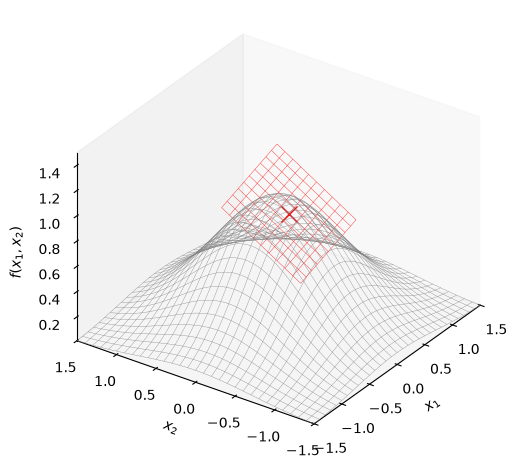

In [77]:
# 一阶近似(线性近似)
approx_first_order = approx_zero_order + df_dx_a_b * (xx_local - x_a) + df_dy_a_b * (yy_local - y_b)

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ax.plot_wireframe(xx, yy, f_xy_zz,
                 color=[0.5, 0.5, 0.5], rstride=num_stride, cstride=num_stride, linewidth=0.25)

ax.plot_wireframe(xx_local, yy_local, approx_first_order,
                 color=[1, 0, 0], rstride=num_stride, cstride=num_stride, linewidth=0.25)

ax.plot(x_a, y_b, f_ab, marker="x", color="r", markersize=12)

ax.set_proj_type("ortho")

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$f(x_1,x_2)$")

ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_zlim(f_xy_zz.min(), 1.5)

ax.view_init(azim=-145, elev=30)
plt.tight_layout()
ax.grid(False)
plt.show()

In [78]:
d2f_dxdx = f_xy.diff(x, 2)
d2f_dxdx

2*(2*x**2 - 1)*exp(-x**2 - y**2)

In [83]:
d2f_dxdx_fcn = lambdify([x, y], d2f_dxdx)
d2f_dxdx_a_b = d2f_dxdx_fcn(x_a, y_b)

In [81]:
d2f_dxdy = f_xy.diff(x, y)
d2f_dxdy

4*x*y*exp(-x**2 - y**2)

In [82]:
d2f_dxdy_fcn = lambdify([x, y], d2f_dxdy)
d2f_dxdy_a_b = d2f_dxdy_fcn(x_a, y_b)

In [84]:
d2f_dydy = f_xy.diff(y, 2)
d2f_dydy

2*(2*y**2 - 1)*exp(-x**2 - y**2)

In [85]:
d2f_dydy_fcn = lambdify([x, y], d2f_dydy)
d2f_dydy_a_b = d2f_dydy_fcn(x_a, y_b)

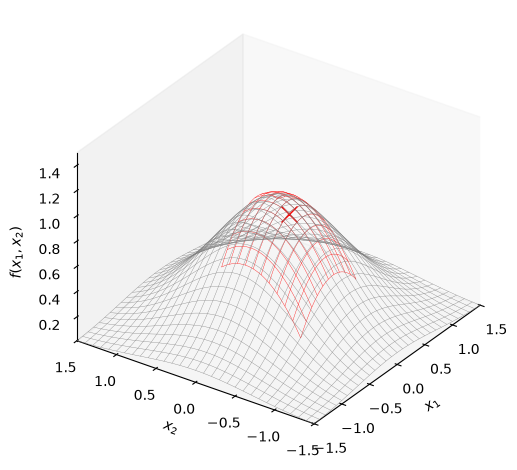

In [87]:
# 二阶近似(二次近似)
approx_second_order = approx_first_order + (d2f_dxdx_a_b * (xx_local - x_a) ** 2 
                                            + 2 * d2f_dxdy_a_b * (xx_local - x_a) * (yy_local - y_b) 
                                            + d2f_dydy_a_b * (yy_local - y_b) ** 2) / 2

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ax.plot_wireframe(xx, yy, f_xy_zz,
                 color=[0.5, 0.5, 0.5], rstride=num_stride, cstride=num_stride, linewidth=0.25)

ax.plot_wireframe(xx_local, yy_local, approx_second_order,
                 color=[1, 0, 0], rstride=num_stride, cstride=num_stride, linewidth=0.25)

ax.plot(x_a, y_b, f_ab, marker="x", color="r", markersize=12)

ax.set_proj_type("ortho")

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$f(x_1,x_2)$")

ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_zlim(f_xy_zz.min(), 1.5)

ax.view_init(azim=-145, elev=30)
plt.tight_layout()
ax.grid(False)
plt.show()

## 17.5 数值分析：估算一阶导数

### 三种方法

本节介绍三种一次导数的数值估算方法：向前差分(forward difference)、向后差分(backward difference)、中心差分(central difference)。
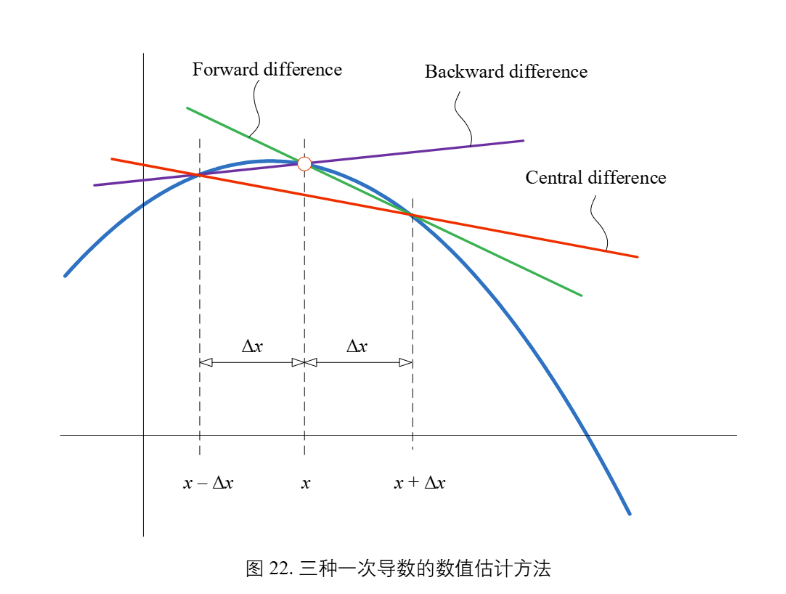

一阶导数向前差分的具体公式为:

$$
f'(x)≈\frac{f(x+\Delta x)-f(x)}{\Delta x}
$$

一阶导数向后差分的公式如下:
$$
f'(x)≈\frac{f(x)-f(x - \Delta x)}{\Delta x}
$$

一阶导数的中心差分形式如下:
$$
f'(x)≈\frac{f(x+\Delta x)-f(x- \Delta x)}{2\Delta x}
$$

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from sympy.abc import x
from sympy import latex, lambdify, diff, sin, log, exp 

In [111]:
# 定义数值求导函数
def num_diff(f, a, method, dx):
    if method == "central":
        return (f(a + dx) - f(a - dx)) / (2 * dx)
    elif method == "forward":
        return (f(a + dx) - f(a)) / dx
    elif method == "backward":
        return (f(a) - f(a - dx)) / dx
    else:
        raise ValueError("Method must be 'central', 'forward' or 'backward'.")

In [112]:
f_x = exp(-x ** 2)
f_x

exp(-x**2)

In [113]:
x_array = np.linspace(-3, 3, 100)
a_array = np.linspace(-2.5, 2.5, 11)

In [114]:
f_x_fcn = lambdify(x, f_x)
f_x_array = f_x_fcn(x_array)

In [115]:
f_x_1_diff = diff(f_x, x)
f_x_1_diff

-2*x*exp(-x**2)

In [116]:
f_x_1_diff_fcn = lambdify(x, f_x_1_diff)
f_x_1_diff_array = f_x_1_diff_fcn(x_array)

In [117]:
# 数值求导方法比较
dx = 0.2 # 步长

diff_central = num_diff(f_x_fcn, a_array, "central", dx)
diff_forward = num_diff(f_x_fcn, a_array, "forward", dx)
diff_backward = num_diff(f_x_fcn, a_array, "backward", dx)

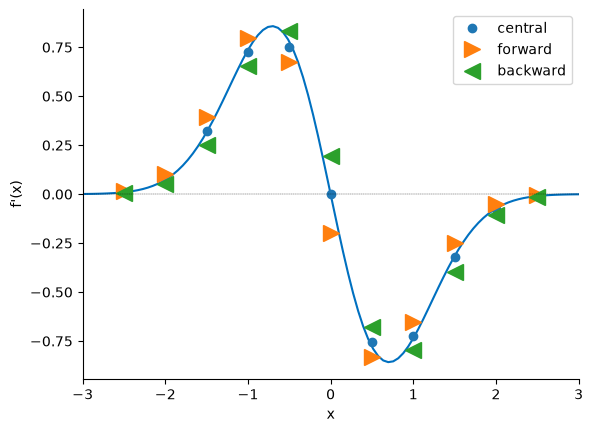

In [119]:
fig, ax = plt.subplots()

ax.plot(x_array, f_x_1_diff_array, "#0070C0", linewidth=1.5)

ax.plot(a_array, diff_central, marker=".", markersize=12, linestyle="none", label="central")
ax.plot(a_array, diff_forward, marker=">", markersize=12, linestyle="none", label="forward")
ax.plot(a_array, diff_backward, marker="<", markersize=12, linestyle="none", label="backward")

ax.set_xlabel("x")
ax.set_ylabel("f'(x)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim((x_array.min(), x_array.max()))
plt.axhline(y=0, color="k", linestyle="--", linewidth=0.25)
plt.legend()

Text(0, 0.5, "f'(x)")

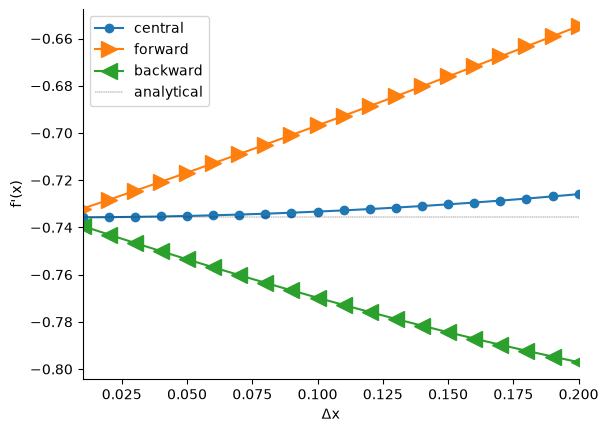

In [120]:
# 不同步长下的数值导数
dx_array = np.linspace(0.01, 0.2, 20)

a = 1 # 求导点

diff_central = num_diff(f_x_fcn, a, "central", dx_array)
diff_forward = num_diff(f_x_fcn, a, "forward", dx_array)
diff_backward = num_diff(f_x_fcn, a, "backward", dx_array)

f_x_1_diff_a = f_x_1_diff_fcn(a)

fig, ax = plt.subplots()

ax.plot(dx_array, diff_central, marker=".", markersize=12, linewidth=1.5, label="central")
ax.plot(dx_array, diff_forward, marker=">", markersize=12, linewidth=1.5, label="forward")
ax.plot(dx_array, diff_backward, marker="<", markersize=12, linewidth=1.5, label="backward")

plt.axhline(y=f_x_1_diff_a, color="k", linestyle="--", linewidth=0.25, label="analytical")

ax.set_xlim(dx_array.min(), dx_array.max())
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.legend()
ax.set_xlabel("\u0394x")
ax.set_ylabel("f'(x)")